JS04 Praktikum 2 - K-Means: blobs, EM manual, digits, kompresi citra.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("kmeans_konsep.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js04-klasterisasi\praktikum-2


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import mode
from sklearn.cluster import KMeans, MiniBatchKMeans, SpectralClustering
from sklearn.datasets import load_digits, load_sample_image, make_blobs, make_moons
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix, pairwise_distances_argmin

sns.set()
OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(exist_ok=True)

In [3]:
def save(name):
    plt.savefig(OUT / name, dpi=110, bbox_inches="tight")


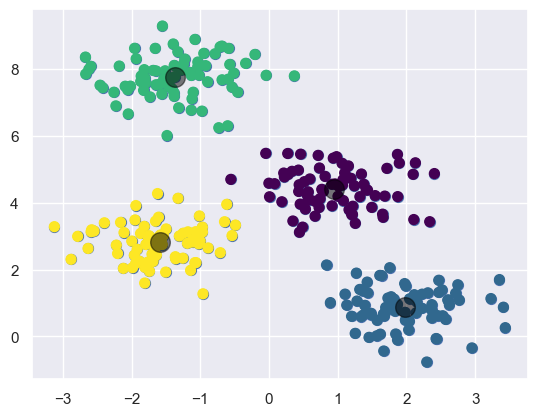

In [4]:
# --- Pengantar k-Means -------------------------------------------------------
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)
plt.scatter(X[:, 0], X[:, 1], s=50)
save("01_blobs.png")

kmeans = KMeans(n_clusters=4, random_state=0).fit(X)
y_kmeans = kmeans.predict(X)
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap="viridis")
plt.scatter(*kmeans.cluster_centers_.T, c="black", s=200, alpha=0.5)
save("02_blobs_kmeans.png")

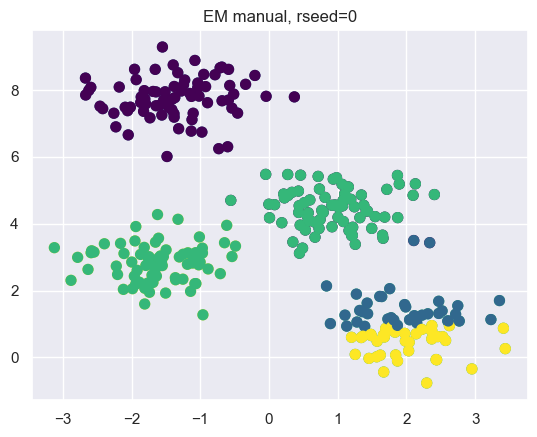

In [5]:
# --- Expectation-Maximization manual ----------------------------------------
def find_clusters(X, n_clusters, rseed=2):
    rng = np.random.RandomState(rseed)
    centers = X[rng.permutation(X.shape[0])[:n_clusters]]
    while True:
        labels = pairwise_distances_argmin(X, centers)
        new_centers = np.array([X[labels == i].mean(0) for i in range(n_clusters)])
        if np.all(centers == new_centers):
            break
        centers = new_centers
    return centers, labels


for seed, name in [(2, "03_em_rseed2.png"), (0, "04_em_rseed0.png")]:
    centers, labels = find_clusters(X, 4, rseed=seed)
    plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap="viridis")
    plt.title(f"EM manual, rseed={seed}")
    save(name)

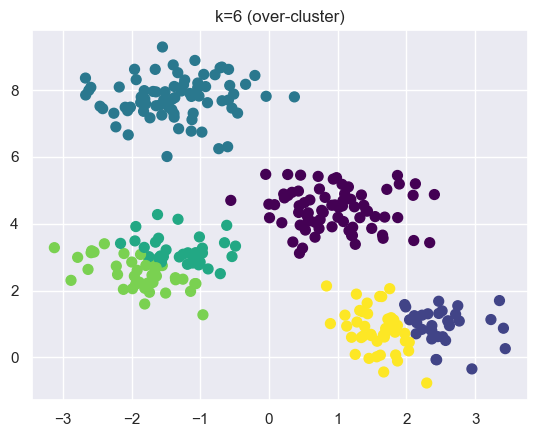

In [6]:
# k terlalu besar
labels = KMeans(6, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap="viridis")
plt.title("k=6 (over-cluster)")
save("05_terlalu_banyak_k.png")

C:\code\pemmes26\.venv\lib\site-packages\sklearn\manifold\_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


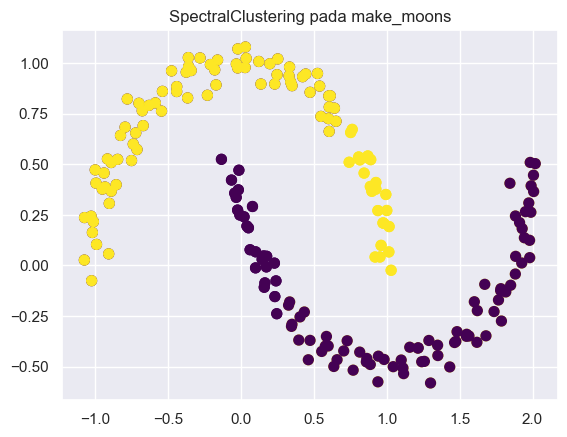

In [7]:
# --- Batas klaster tidak linier: moons --------------------------------------
Xm, ym = make_moons(200, noise=0.05, random_state=0)
labels = KMeans(2, random_state=0).fit_predict(Xm)
plt.scatter(Xm[:, 0], Xm[:, 1], c=labels, s=50, cmap="viridis")
plt.title("K-Means pada make_moons")
save("06_moons_kmeans.png")

labels = SpectralClustering(
    n_clusters=2, affinity="nearest_neighbors", assign_labels="kmeans", random_state=0
).fit_predict(Xm)
plt.scatter(Xm[:, 0], Xm[:, 1], c=labels, s=50, cmap="viridis")
plt.title("SpectralClustering pada make_moons")
save("07_moons_spectral.png")

In [8]:
# --- Studi kasus 1: karakter angka ------------------------------------------
digits = load_digits()
print("digits.data.shape:", digits.data.shape)

digits.data.shape: (1797, 64)


centers shape: (10, 64)


Akurasi K-Means pada digits: 0.7440


Akurasi K-Means setelah t-SNE: 0.8620


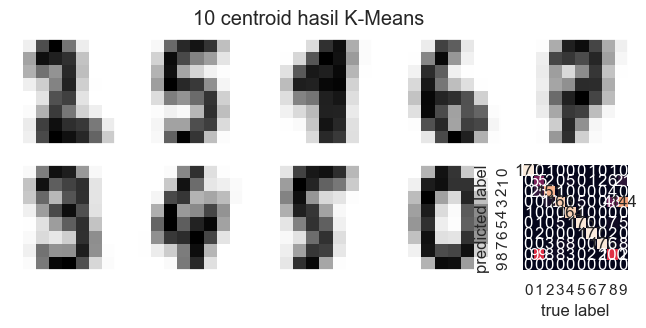

In [9]:
def majority_labels(clusters, target):
    labels = np.zeros_like(clusters)
    for i in range(10):
        labels[clusters == i] = mode(target[clusters == i], keepdims=False)[0]
    return labels


kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits.data)
print("centers shape:", kmeans.cluster_centers_.shape)

fig, ax = plt.subplots(2, 5, figsize=(8, 3))
for axi, center in zip(ax.flat, kmeans.cluster_centers_.reshape(10, 8, 8)):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation="nearest", cmap=plt.cm.binary)
fig.suptitle("10 centroid hasil K-Means")
save("08_digit_centroids.png")

labels = majority_labels(clusters, digits.target)
print(f"Akurasi K-Means pada digits: {accuracy_score(digits.target, labels):.4f}")

mat = confusion_matrix(digits.target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt="d",
            cbar=False, xticklabels=digits.target_names, yticklabels=digits.target_names)
plt.xlabel("true label")
plt.ylabel("predicted label")
save("09_digit_confusion.png")

tsne = TSNE(n_components=2, init="random", random_state=0, max_iter=1000)
digits_proj = tsne.fit_transform(digits.data)
clusters = KMeans(n_clusters=10, random_state=0).fit_predict(digits_proj)
labels = majority_labels(clusters, digits.target)
print(f"Akurasi K-Means setelah t-SNE: {accuracy_score(digits.target, labels):.4f}")

In [10]:
# --- Studi kasus 2: kompresi citra ------------------------------------------
flower = load_sample_image("flower.jpg")
print("flower.shape:", flower.shape)

data = (flower / 255.0).reshape(-1, 3)
print("data.shape:", data.shape)

flower.shape: (427, 640, 3)
data.shape: (273280, 3)



Semua gambar tersimpan di C:\code\pemmes26\js04-klasterisasi\praktikum-2\output


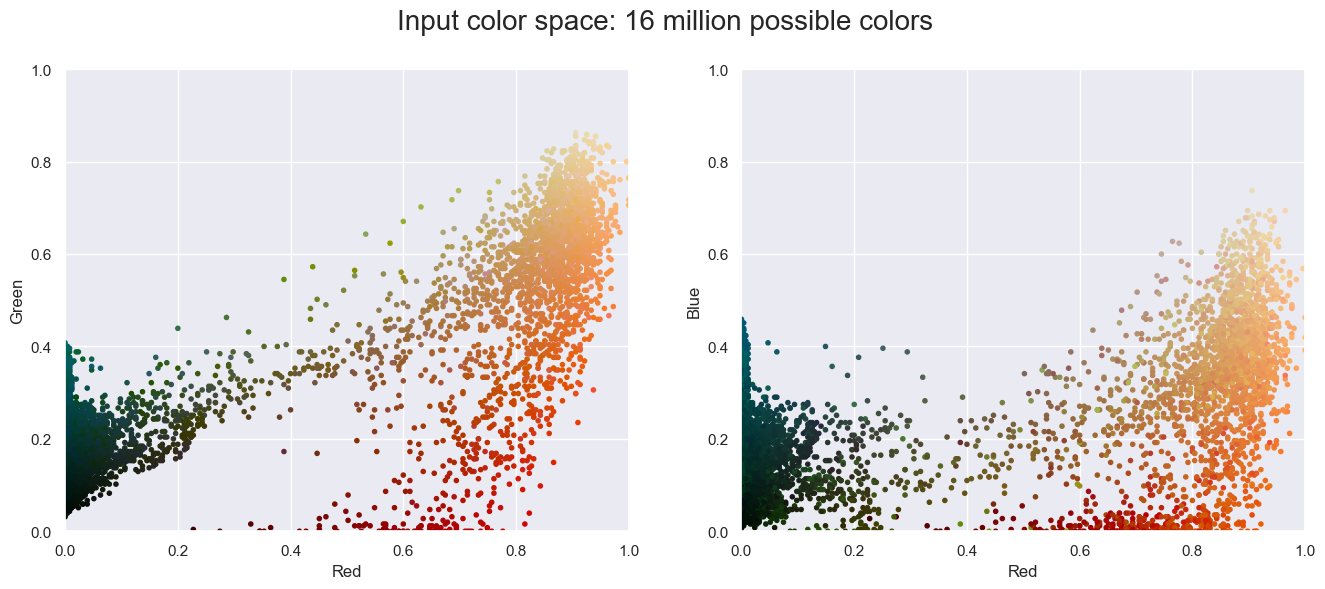

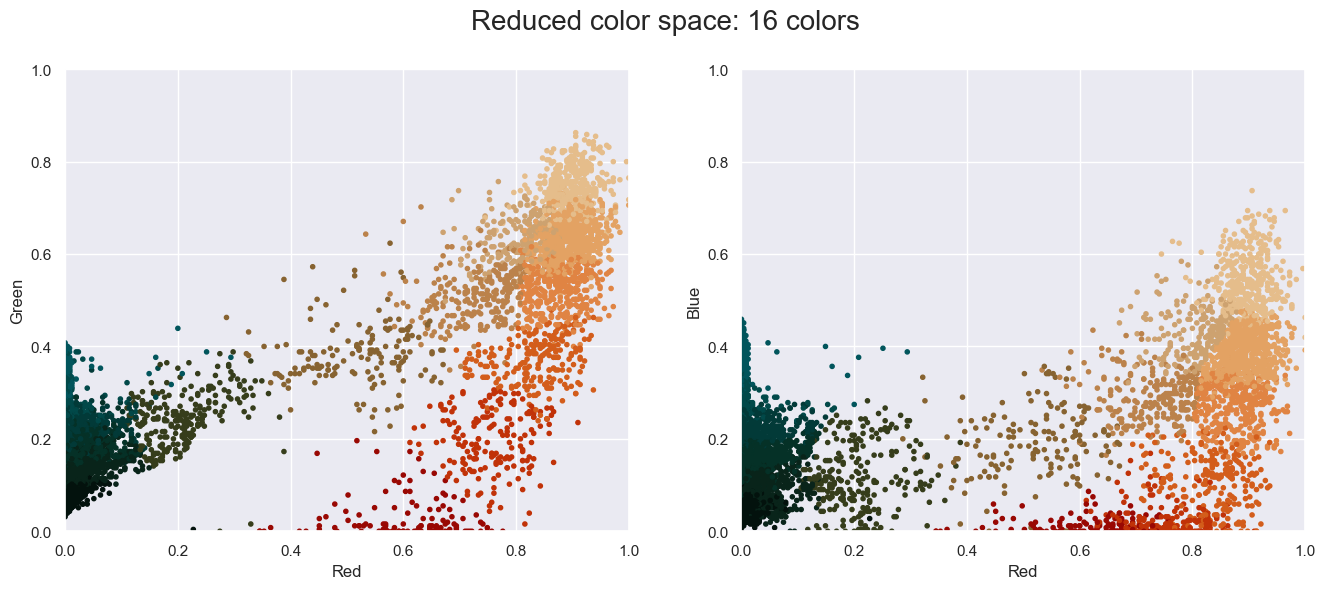

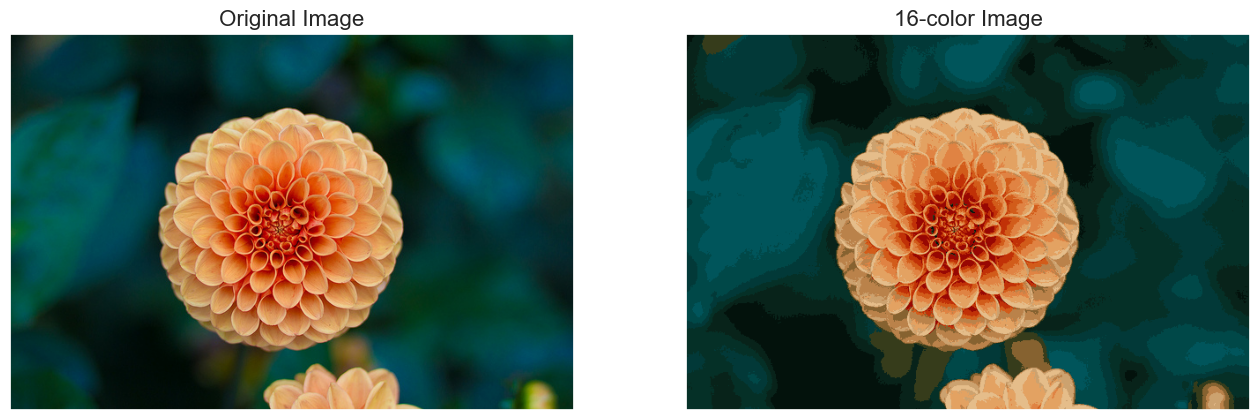

In [11]:
def plot_pixels(data, title, colors=None, N=10000):
    colors = data if colors is None else colors
    i = np.random.RandomState(0).permutation(data.shape[0])[:N]
    colors, R, G, B = colors[i], *data[i].T
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker=".")
    ax[0].set(xlabel="Red", ylabel="Green", xlim=(0, 1), ylim=(0, 1))
    ax[1].scatter(R, B, color=colors, marker=".")
    ax[1].set(xlabel="Red", ylabel="Blue", xlim=(0, 1), ylim=(0, 1))
    fig.suptitle(title, size=20)


plot_pixels(data, title="Input color space: 16 million possible colors")
save("10_warna_asli.png")

kmeans = MiniBatchKMeans(16, random_state=0, n_init=3).fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]
plot_pixels(data, colors=new_colors, title="Reduced color space: 16 colors")
save("11_warna_16.png")

fig, ax = plt.subplots(1, 2, figsize=(16, 6), subplot_kw=dict(xticks=[], yticks=[]))
ax[0].imshow(flower)
ax[0].set_title("Original Image", size=16)
ax[1].imshow(new_colors.reshape(flower.shape))
ax[1].set_title("16-color Image", size=16)
save("12_perbandingan_citra.png")

print("\nSemua gambar tersimpan di", OUT)